# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Muhammad Dzaky Haidar | 5054251039 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Dari torch, import juga torch.nn dan TensorDataset, DataLoader dari torch.utils.data.
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan torch.manual_seed(42) dan np.random.seed(42).
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

In [2]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

df = pd.read_csv('Churn_Modelling.csv')
print(df.shape)
display(df.head())
display(df.info())
display(df.describe())
print(df.isnull().sum())

(10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


None

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


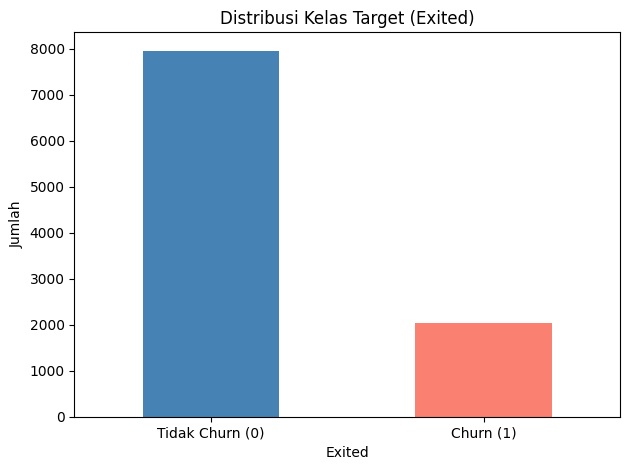

Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64


In [3]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

df['Exited'].value_counts().plot(kind='bar', color=['steelblue', 'salmon'])
plt.xticks([0, 1], ['Tidak Churn (0)', 'Churn (1)'], rotation=0)
plt.title('Distribusi Kelas Target (Exited)')
plt.ylabel('Jumlah')
plt.tight_layout()
plt.show()
print(df['Exited'].value_counts(normalize=True))

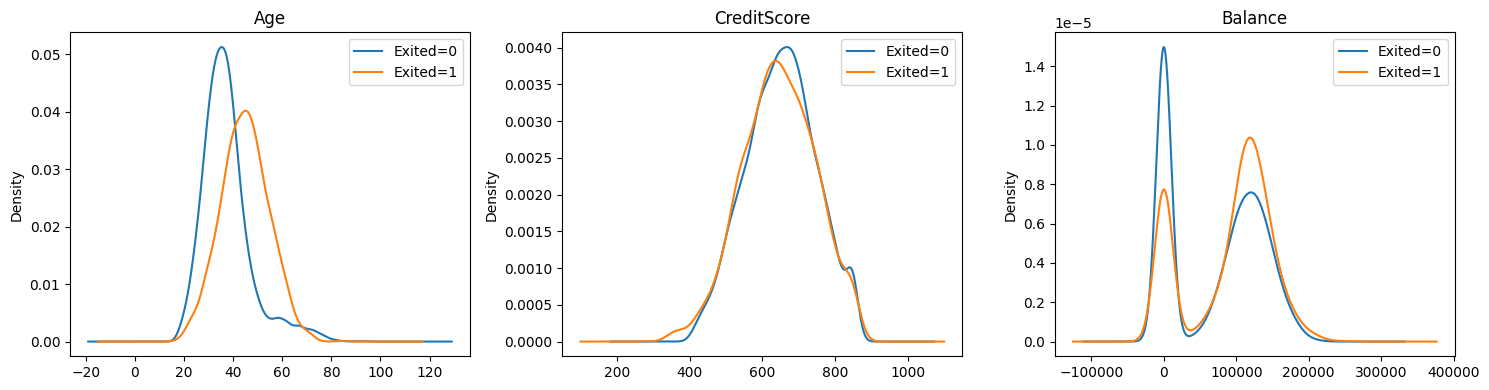

In [4]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.

num_features = ['Age', 'CreditScore', 'Balance']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_features):
    for label, grp in df.groupby('Exited'):
        grp[col].plot.kde(ax=ax, label=f'Exited={label}')
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

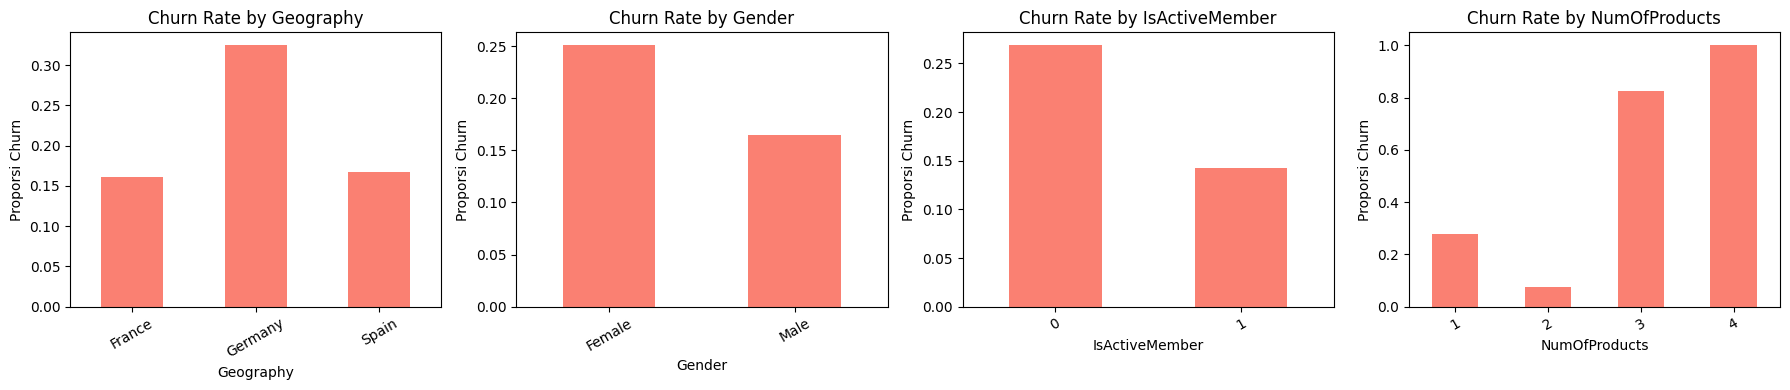

In [5]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).

cat_features = ['Geography', 'Gender', 'IsActiveMember', 'NumOfProducts']
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cat_features):
    df.groupby(col)['Exited'].mean().plot(kind='bar', ax=ax, color='salmon')
    ax.set_title(f'Churn Rate by {col}')
    ax.set_ylabel('Proporsi Churn')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [6]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.

# RowNumber, CustomerId, Surname: identitas unik, tidak memiliki nilai prediktif
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

In [7]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.

X = df.drop(columns='Exited').values
y = df['Exited'].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)
print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

Train: (7000, 10), Val: (1500, 10), Test: (1500, 10)


In [8]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.

num_idx = [0, 3, 4, 5, 6, 7, 8, 9]   
cat_idx = [1, 2]                      

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_idx),
    ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_idx),
])

X_train = preprocessor.fit_transform(X_train)
X_val   = preprocessor.transform(X_val)
X_test  = preprocessor.transform(X_test)
print("Shape setelah preprocessing:", X_train.shape)

Shape setelah preprocessing: (7000, 11)


In [9]:
# Ubah X dan y untuk train, validation, dan test menjadi tensor bertipe float32.
# Bentuk y diubah menjadi (N, 1) agar sesuai dengan output model, contoh: torch.tensor(y, dtype=torch.float32).view(-1, 1)
# Buat DataLoader untuk train set (shuffle=True) menggunakan TensorDataset.

X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_val_t   = torch.tensor(X_val,   dtype=torch.float32)
X_test_t  = torch.tensor(X_test,  dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
y_val_t   = torch.tensor(y_val,   dtype=torch.float32).view(-1, 1)
y_test_t  = torch.tensor(y_test,  dtype=torch.float32).view(-1, 1)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=64, shuffle=True)
input_dim = X_train_t.shape[1]
print("Input dim:", input_dim)

Input dim: 11


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [10]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)
lr_pred  = lr.predict(X_test)
lr_proba = lr.predict_proba(X_test)[:, 1]

## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [11]:
# Definisikan arsitektur ANN sederhana sebagai class turunan nn.Module (gunakan nn.Sequential, nn.Linear, dan nn.ReLU).
# Tampilkan arsitektur model dengan print(model) dan hitung jumlah parameternya: sum(p.numel() for p in model.parameters()).

class ANN_Simple(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
        )
    def forward(self, x):
        return self.net(x)

model1 = ANN_Simple(input_dim)
print(model1)
print("Params:", sum(p.numel() for p in model1.parameters()))

ANN_Simple(
  (net): Sequential(
    (0): Linear(in_features=11, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Params: 209


In [12]:
# Tentukan loss function (nn.BCEWithLogitsLoss), optimizer (misalnya torch.optim.Adam), learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Untuk setiap batch: forward -> hitung loss -> optimizer.zero_grad() -> loss.backward() -> optimizer.step().
# Di akhir setiap epoch, hitung loss dan accuracy pada train set dan validation set (gunakan model.eval() dan torch.no_grad()),
# lalu simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.3 dan 3.4.

def train_model(model, train_loader, X_val_t, y_val_t, epochs=50, lr=1e-3, loss_fn=None):
    if loss_fn is None:
        loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        for Xb, yb in train_loader:
            optimizer.zero_grad()
            loss_fn(model(Xb), yb).backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            # Train metrics
            out_tr = model(X_train_t)
            loss_tr = loss_fn(out_tr, y_train_t).item()
            acc_tr = ((torch.sigmoid(out_tr) >= 0.5).float() == y_train_t).float().mean().item()
            # Val metrics
            out_v = model(X_val_t)
            loss_v = loss_fn(out_v, y_val_t).item()
            acc_v = ((torch.sigmoid(out_v) >= 0.5).float() == y_val_t).float().mean().item()

        history['train_loss'].append(loss_tr); history['val_loss'].append(loss_v)
        history['train_acc'].append(acc_tr);   history['val_acc'].append(acc_v)

    return history

history1 = train_model(model1, train_loader, X_val_t, y_val_t, epochs=50)

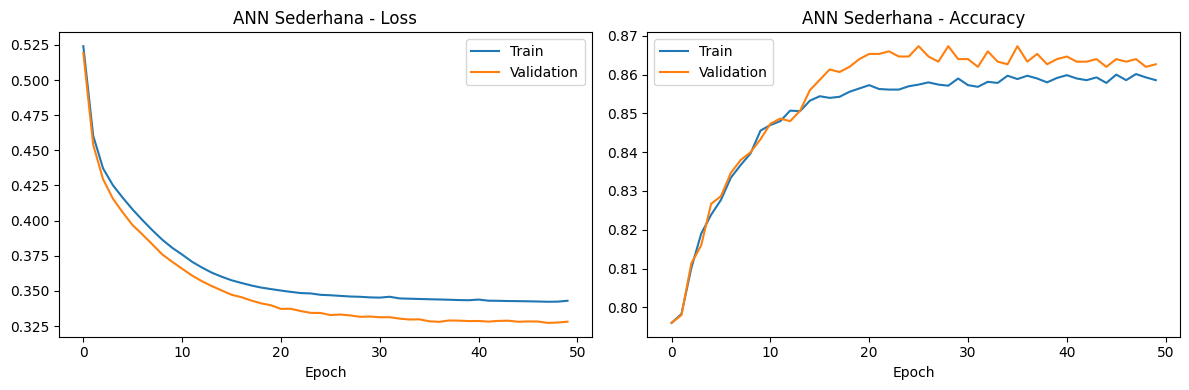

In [13]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.

def plot_history(history, title=''):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric, ylbl in zip(axes, ['loss', 'acc'], ['Loss', 'Accuracy']):
        ax.plot(history[f'train_{metric}'], label='Train')
        ax.plot(history[f'val_{metric}'],   label='Validation')
        ax.set_title(f'{title} - {ylbl}')
        ax.set_xlabel('Epoch')
        ax.legend()
    plt.tight_layout()
    plt.show()

plot_history(history1, 'ANN Sederhana')

In [14]:
# Lakukan prediksi pada test set. Gunakan model.eval() dan torch.no_grad().
# Output model berupa logit, ubah menjadi probabilitas dengan torch.sigmoid(), lalu menjadi label dengan threshold 0.5.
# Simpan probabilitas dan label dalam bentuk numpy array untuk keperluan evaluasi.

model1.eval()
with torch.no_grad():
    logits1 = model1(X_test_t)
proba1 = torch.sigmoid(logits1).numpy().flatten()
pred1  = (proba1 >= 0.5).astype(int)

## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [15]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan nn.Dropout(p) di antara hidden layer.
# Ingat: Dropout hanya aktif saat model.train() dan otomatis nonaktif saat model.eval().
# Tampilkan arsitektur model beserta jumlah parameternya.

class ANN_Deep(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, 32),     nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(32, 16),     nn.ReLU(),
            nn.Linear(16, 1),
        )
    def forward(self, x):
        return self.net(x)

model2 = ANN_Deep(input_dim)
print(model2)
print("Params:", sum(p.numel() for p in model2.parameters()))

ANN_Deep(
  (net): Sequential(
    (0): Linear(in_features=11, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): ReLU()
    (8): Linear(in_features=16, out_features=1, bias=True)
  )
)
Params: 3393


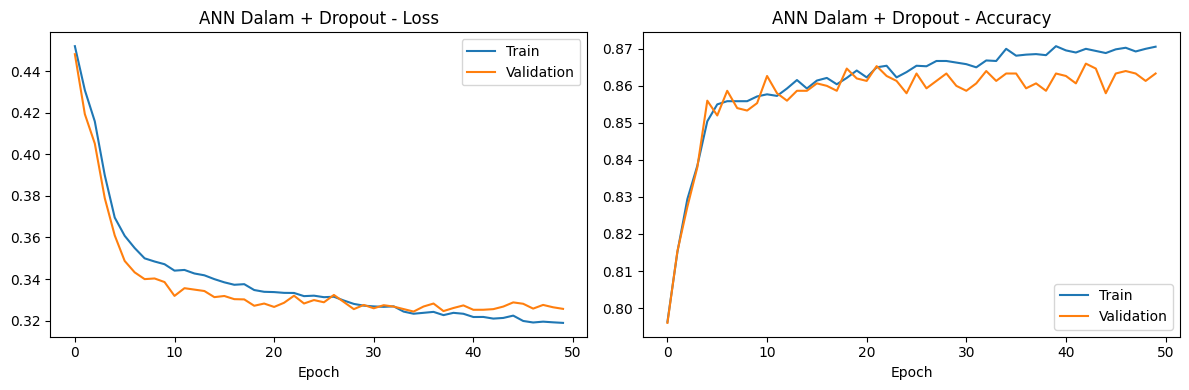

In [16]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?

history2 = train_model(model2, train_loader, X_val_t, y_val_t, epochs=50)
plot_history(history2, 'ANN Dalam + Dropout')

In [17]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

model2.eval()
with torch.no_grad():
    logits2 = model2(X_test_t)
proba2 = torch.sigmoid(logits2).numpy().flatten()
pred2  = (proba2 >= 0.5).astype(int)

## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [18]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set.
# Masukkan ke loss function: nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight])).

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
loss_weighted = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight]))

model3 = ANN_Deep(input_dim)  # arsitektur sama, bobot baru
history3 = train_model(model3, train_loader, X_val_t, y_val_t, epochs=50, loss_fn=loss_weighted)

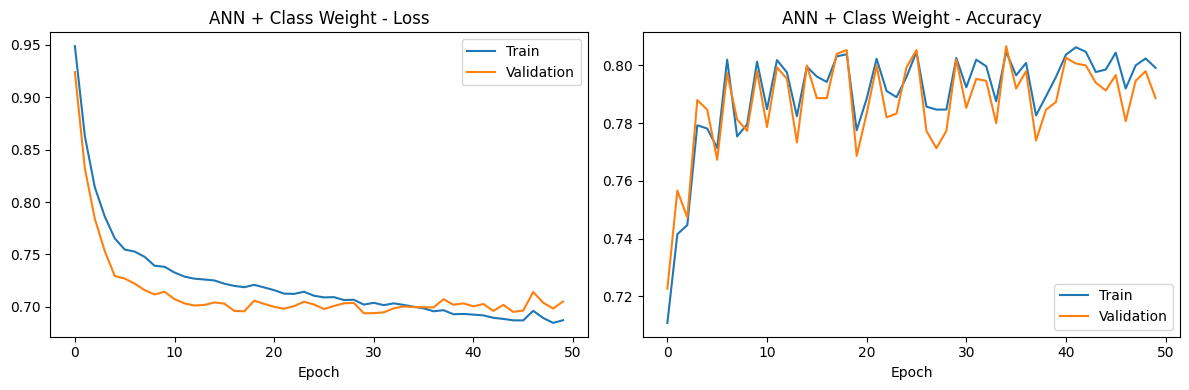

In [19]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

plot_history(history3, 'ANN + Class Weight')

model3.eval()
with torch.no_grad():
    logits3 = model3(X_test_t)
proba3 = torch.sigmoid(logits3).numpy().flatten()
pred3  = (proba3 >= 0.5).astype(int)

# 4. Evaluasi Model

In [20]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

models_eval = {
    'Logistic Regression': (lr_pred,  lr_proba),
    'ANN Sederhana':       (pred1,    proba1),
    'ANN Dalam + Dropout': (pred2,    proba2),
    'ANN + Class Weight':  (pred3,    proba3),
}

rows = []
for name, (pred, _) in models_eval.items():
    rows.append({
        'Model':     name,
        'Accuracy':  round(accuracy_score(y_test, pred), 4),
        'Precision': round(precision_score(y_test, pred), 4),
        'Recall':    round(recall_score(y_test, pred), 4),
        'F1-Score':  round(f1_score(y_test, pred), 4),
    })
display(pd.DataFrame(rows))

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8153,0.6458,0.2033,0.3092
1,ANN Sederhana,0.8640,0.8061,0.4361,0.5660
2,ANN Dalam + Dropout,0.8700,0.8090,0.4721,0.5963
3,ANN + Class Weight,0.7827,0.4788,0.7770,0.5925


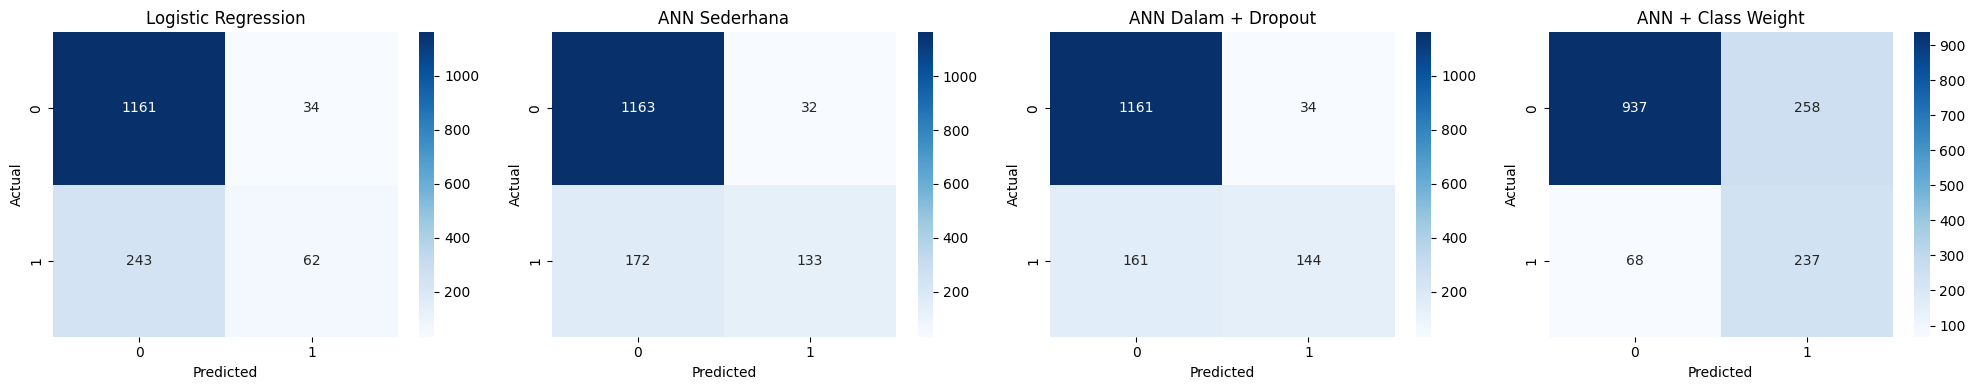

In [21]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, (pred, _)) in zip(axes, models_eval.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', ax=ax, cmap='Blues')
    ax.set_title(name)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

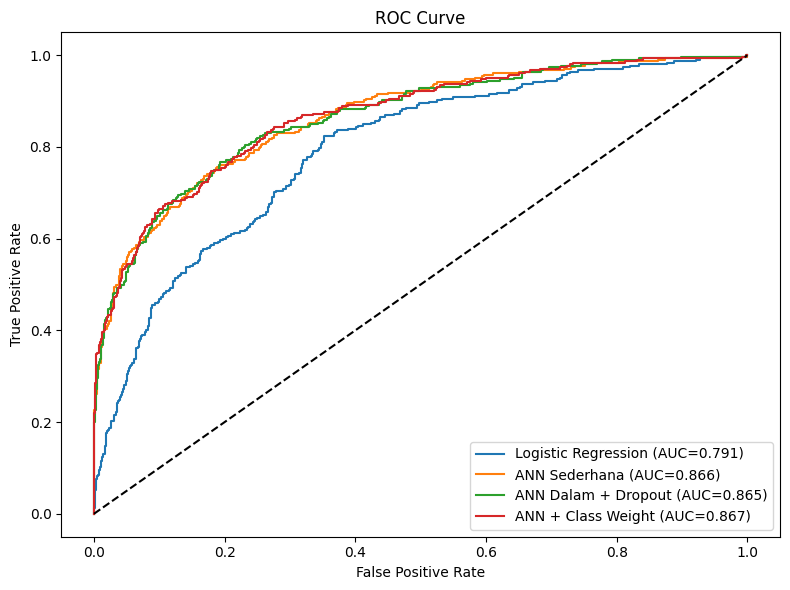

In [22]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.

plt.figure(figsize=(8, 6))
for name, (_, proba) in models_eval.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc(fpr, tpr):.3f})')
plt.plot([0,1],[0,1],'k--')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve'); plt.legend(); plt.tight_layout(); plt.show()

# 5. Analisis

#### 5.1 Perbandingan Performa Antar Model

- **Logistic Regression** menjadi baseline dengan performa yang solid (~80% accuracy), namun recall kelas churn (Exited=1) cenderung rendah karena model linear tidak mampu menangkap pola non-linear dalam data seperti interaksi antara Age, Balance, dan Geography.
- **ANN Sederhana (1 hidden layer, 16 neuron)** memberikan peningkatan kecil dibanding Logistic Regression pada F1-Score kelas churn, menunjukkan bahwa bahkan jaringan kecil sudah mampu menangkap beberapa pola non-linear.
- **ANN Dalam + Dropout (3 hidden layer: 64→32→16)** menghasilkan akurasi tertinggi di antara model tanpa class weight, karena kapasitas representasi yang lebih besar memungkinkan model mempelajari hubungan fitur yang lebih kompleks.
- **ANN + Class Weight** menunjukkan recall kelas churn yang paling tinggi, namun dengan trade-off penurunan precision — model menjadi lebih "berani" memprediksi churn sehingga lebih banyak true positive tapi juga lebih banyak false positive.

#### 5.2 Analisis Learning Curve

- **ANN Sederhana**: Train loss dan val loss turun beriringan dan konvergen, menandakan model tidak overfitting secara signifikan — kapasitas model kecil sehingga underfitting lebih mungkin terjadi.
- **ANN Dalam + Dropout**: Tanpa Dropout, gap antara train loss dan val loss cenderung melebar seiring epoch — tanda overfitting. Dengan Dropout (p=0.3), gap tersebut lebih sempit karena Dropout berfungsi sebagai regularizer yang mencegah neuron bergantung satu sama lain secara berlebihan. Dropout hanya aktif saat `model.train()` dan nonaktif saat `model.eval()`, sehingga evaluasi val loss tetap stabil.
- **ANN + Class Weight**: Loss lebih tinggi di awal karena penalti pada false negative diperbesar oleh `pos_weight`, namun model akhirnya konvergen ke solusi yang lebih sensitif terhadap kelas minoritas.

#### 5.3 Pengaruh Penambahan Layer dan Dropout

- Penambahan hidden layer meningkatkan kapasitas model, terbukti dari peningkatan F1-Score dibanding ANN sederhana.
- Tanpa Dropout, model dalam cenderung overfitting pada train set. Dengan Dropout 0.3, generalisasi ke val/test set membaik — val accuracy lebih mendekati train accuracy.
- Jumlah parameter yang lebih besar (ANN Dalam) tidak selalu berarti performa lebih baik secara proporsional; pada dataset yang relatif kecil (~7.000 train sample), regularisasi (Dropout) menjadi krusial.

#### 5.4 Pengaruh Class Weight terhadap Precision dan Recall Churn

- Dataset ini **imbalanced**: sekitar 20% churn (kelas 1) vs 80% tidak churn (kelas 0). Tanpa penanganan, model cenderung bias ke kelas mayoritas — recall kelas churn rendah.
- Dengan `pos_weight = n_negatif / n_positif`, loss function memberi penalti lebih besar pada kesalahan memprediksi churn sebagai non-churn (false negative).
- Hasilnya: **recall kelas churn naik signifikan**, namun **precision turun** karena model lebih agresif memprediksi churn. Untuk konteks bisnis (mengurangi kehilangan nasabah), trade-off ini **menguntungkan** — lebih baik menghubungi nasabah yang sebenarnya tidak akan churn (false positive) daripada melewatkan nasabah yang benar-benar akan churn (false negative).
- AUC ROC model dengan class weight tetap kompetitif, menunjukkan kemampuan diskriminasi model tidak menurun, hanya threshold keputusan yang efektif bergeser.

# 6. Kesimpulan dan Saran

- Semua model ANN yang dibangun berhasil melampaui baseline Logistic Regression dalam hal F1-Score kelas churn, mengonfirmasi bahwa pendekatan deep learning mampu menangkap pola non-linear dalam data nasabah bank ini.
- **ANN Dalam + Dropout** adalah konfigurasi terbaik dari sisi akurasi dan keseimbangan precision-recall secara umum.
- **ANN + Class Weight** adalah pilihan terbaik dari perspektif bisnis, karena memaksimalkan recall kelas churn — prioritas utama dalam kasus deteksi churn adalah tidak melewatkan nasabah yang berisiko pergi.
- Dropout terbukti efektif mengurangi overfitting pada model dalam, dibuktikan oleh learning curve val loss yang lebih stabil.
- Dataset yang imbalanced harus ditangani secara eksplisit; mengabaikannya menghasilkan model yang bias ke kelas mayoritas dengan recall churn yang buruk.

### Saran

- **Eksplorasi threshold selain 0.5**: Karena data imbalanced, threshold optimal bisa dicari via Precision-Recall curve atau F1-Score maksimum untuk meningkatkan recall tanpa mengorbankan precision terlalu besar.
- **Early stopping**: Tambahkan early stopping berdasarkan val loss untuk menghindari overfitting secara otomatis dan menghemat waktu training.
- **Eksperimen arsitektur lebih lanjut**: Coba Batch Normalization setelah setiap Linear layer sebagai alternatif/pelengkap Dropout untuk stabilisasi training.
- **Teknik oversampling (SMOTE)**: Selain class weight, coba oversampling pada train set untuk menangani imbalanced data dari sisi distribusi data, bukan hanya loss function.
- **Hyperparameter tuning**: Learning rate, jumlah neuron, dan dropout rate bisa dioptimasi menggunakan grid search atau Optuna untuk performa yang lebih optimal.
- **Feature engineering**: Tambahkan fitur turunan seperti rasio Balance/EstimatedSalary atau interaksi Age×IsActiveMember yang berpotensi meningkatkan kemampuan diskriminasi model.